In [2]:
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 2.2 MB/s eta 0:00:00 MB/s eta 0:00:01:01


In [3]:
import networkx as nx


In [ ]:
G = nx.Graph()  # empty graph

In [ ]:
G.add_node(1)

In [ ]:
G.add_nodes_from([2,3]) # add_nodes_from expects iterable, nodes are element of iterable

In [7]:
# node attributes
G.add_nodes_from([(4, {"color": "red"}), (5, {"color": "green"})])


In [ ]:
# nodes from one graph can be incorporated to another
H = nx.path_graph(10)
G.add_nodes_from(H)

In [11]:
G.add_node(H)

In [12]:
G.add_edge(1,2)

In [13]:
e = (2,3)
G.add_edge(*e) # unpack edge tuple 

In [14]:
G.add_edges_from([(1, 2), (1, 3)])

In [15]:
G.add_edges_from(H.edges)

In [17]:
G.clear()

In [18]:
G.add_edges_from([(1, 2), (1, 3)])
G.add_node(1)
G.add_edge(1, 2)
G.add_node("spam")        # adds node "spam"
G.add_nodes_from("spam")  # adds 4 nodes: 's', 'p', 'a', 'm'
G.add_edge(3, 'm')

In [19]:
G.number_of_nodes()

8

In [20]:
H.number_of_nodes()

10

In [21]:
G.number_of_edges()

3

In [22]:
DG = nx.DiGraph()
DG.add_edge(2, 1)   # adds the nodes in order 2, 1
DG.add_edge(1, 3)
DG.add_edge(2, 4)
DG.add_edge(1, 2)
assert list(DG.successors(2)) == [1, 4]
assert list(DG.edges) == [(2, 1), (2, 4), (1, 3), (1, 2)]

In [23]:
list(G.nodes)

[1, 2, 3, 'spam', 's', 'p', 'a', 'm']

In [24]:
list(G.edges)

[(1, 2), (1, 3), (3, 'm')]

In [25]:
list(H.nodes)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [26]:
list(DG.nodes)

[2, 1, 3, 4]

In [27]:
list(DG.edges)

[(2, 1), (2, 4), (1, 3), (1, 2)]

In [ ]:
list(G.adj[1]) # orlist(G.neighbors(1))

[2, 3]

In [29]:
G.degree[1]  # the number of edges incident to 1

2

In [30]:
G.edges([2, 'm'])

EdgeDataView([(2, 1), ('m', 3)])

In [31]:
G.degree([2, 3])


DegreeView({2: 1, 3: 2})

In [32]:
G.nodes["spam"]["color"] = "blue"
G.edges[(1, 2)]["weight"] = 10

In [37]:
G.nodes()

NodeView((1, 2, 3, 'spam', 's', 'p', 'a', 'm'))

In [43]:
list(G.nodes())

[1, 3, 'spam']

In [45]:
list(G.edges)

[(1, 3)]

In [ ]:
G.nodes(data = True) # attributes

NodeDataView({1: {}, 2: {}, 3: {}, 'spam': {'color': 'blue'}, 's': {}, 'p': {}, 'a': {}, 'm': {}})

In [40]:
G.nodes(data="color")


NodeDataView({1: None, 2: None, 3: None, 'spam': 'blue', 's': None, 'p': None, 'a': None, 'm': None}, data='color')

In [ ]:
G.remove_node(2)
G.remove_nodes_from("spam") # 's', 'p', 'a','m'

In [42]:
list(G.nodes)

[1, 3, 'spam']

In [47]:
list(G.edges)

[(1, 3)]

In [48]:
G.remove_edge(1, 3)

In [49]:
list(G.nodes)

[1, 3, 'spam']

In [50]:
list(G.edges)

[]

In [ ]:
G.add_edge(1, 2)
H = nx.DiGraph(G)  # create a DiGraph using the connections from G
list(H.edges())

[(1, 2), (2, 1)]

In [53]:
list(H.nodes)

[1, 3, 'spam', 2]

In [56]:
edgelist = [(0, 1), (1, 2), (2, 3)]
H = nx.Graph(edgelist)  # create a graph from an edge list
list(H.edges())

[(0, 1), (1, 2), (2, 3)]

In [57]:
adjacency_dict = {0: (1, 2), 1: (0, 2), 2: (0, 1)}
H = nx.Graph(adjacency_dict)  # create a Graph dict mapping nodes to nbrs
list(H.edges())

[(0, 1), (0, 2), (1, 2)]

In [58]:
G = nx.Graph([(1, 2, {"color": "yellow"})])
G[1]  # same as G.adj[1]


AtlasView({2: {'color': 'yellow'}})

In [59]:
G[1][2]


{'color': 'yellow'}

In [60]:
G.edges[1, 2]

{'color': 'yellow'}

In [61]:
G.add_edge(1, 3)
G[1][3]['color'] = "blue"
G.edges[1, 2]['color'] = "red"
G.edges[1, 2]

{'color': 'red'}

In [62]:
FG = nx.Graph()
FG.add_weighted_edges_from([(1, 2, 0.125), (1, 3, 0.75), (2, 4, 1.2), (3, 4, 0.375)])
for n, nbrs in FG.adj.items():
   for nbr, eattr in nbrs.items():
       wt = eattr['weight']
       if wt < 0.5: print(f"({n}, {nbr}, {wt:.3})")

(1, 2, 0.125)
(2, 1, 0.125)
(3, 4, 0.375)
(4, 3, 0.375)


In [63]:
for (u, v, wt) in FG.edges.data('weight'):
    if wt < 0.5:
        print(f"({u}, {v}, {wt:.3})")

(1, 2, 0.125)
(3, 4, 0.375)


In [ ]:
G = nx.Graph(day="Friday")  # graph attributes
G.graph

{'day': 'Friday'}

In [66]:
G.graph['day'] = "Monday"
G.graph


{'day': 'Monday'}

In [67]:
# Node attributes
G.add_node(1, time='5pm')
G.add_nodes_from([3], time='2pm')
G.nodes[1]

{'time': '5pm'}

In [68]:
G.nodes[1]['room'] = 714
G.nodes.data()


NodeDataView({1: {'time': '5pm', 'room': 714}, 3: {'time': '2pm'}})

In [69]:
# Edge attributes
G.add_edge(1, 2, weight=4.7 )
G.add_edges_from([(3, 4), (4, 5)], color='red')
G.add_edges_from([(1, 2, {'color': 'blue'}), (2, 3, {'weight': 8})])
G[1][2]['weight'] = 4.7
G.edges[3, 4]['weight'] = 4.2

In [70]:
# Directed graphs
DG = nx.DiGraph()
DG.add_weighted_edges_from([(1, 2, 0.5), (3, 1, 0.75)])
DG.out_degree(1, weight='weight')


0.5

In [72]:
!pip install matplotlib
import matplotlib.pyplot as plt

  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (11.0 MB)
Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (384 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 3.1 MB/s eta 0:00:000:00:010:00:01:01
Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (

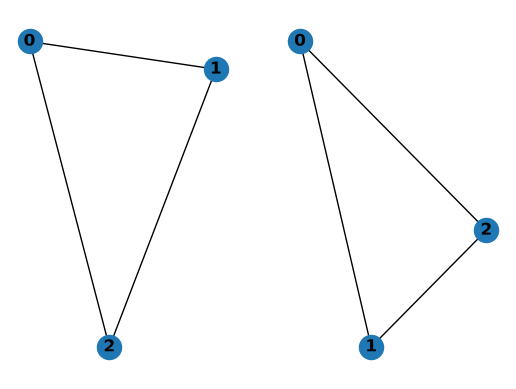

In [76]:
subax1 = plt.subplot(121)
nx.draw(H, with_labels=True, font_weight='bold')
subax2 = plt.subplot(122)
nx.draw_shell(H, nlist=[range(5, 10), range(5)], with_labels=True, font_weight='bold')


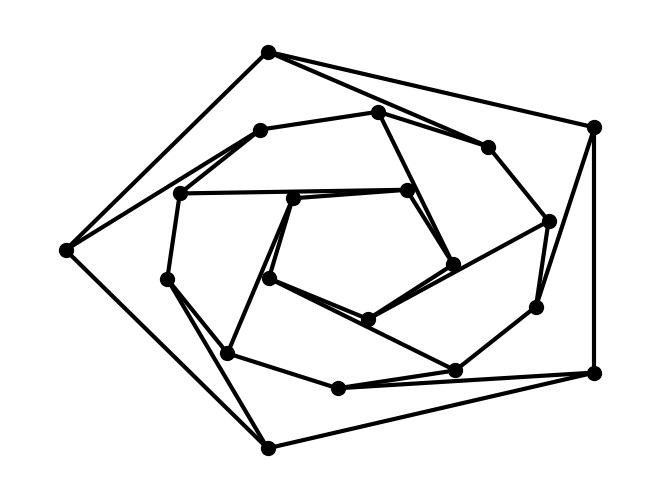

In [86]:
options = {
    'node_color': 'black',
    'node_size': 100,
    'width': 3,
}
G = nx.dodecahedral_graph()
shells = [[2,3,4,5,6], [8, 1, 0, 19, 18, 17, 16, 15, 14, 7], [9, 10, 11, 12, 13]]
nx.draw_shell(G, nlist=shells, **options)

In [82]:
print(G.number_of_nodes())
print(G.number_of_edges())

print(G.degree[0])

20
30
3
